### Imports

In [1]:
import naima
from naima.models import ExponentialCutoffPowerLaw
import astropy.units as u
from astropy.constants import c
import numpy as np
import matplotlib.pyplot as plt

### Define distribution of non-thermal electrons

Stand-alone distribution to compare with:

In [2]:
dist_compare= np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/dist_e.dat")
# dist_compare[:,0] has electron energies in eV
# dist_compare[:,1] has the distribution in 1/erg

Construct the same distribution in naima:

In [3]:
eV_temp=1.602176E-12
e_0=1*u.eV
e_break=1E100*u.eV
alpha_1=2
amplitude = 1.7690615972392788E+043*u.erg/u.eV # Taken from stand-alone code 
alpha_2=0
e_cutoff=1.E13*u.eV
beta=1

Q = naima.models.ExponentialCutoffBrokenPowerLaw( amplitude=amplitude*u.Unit('1/eV'), \
                                                 e_0=e_0, \
                                                 e_break=e_break, \
                                                 alpha_1=alpha_1, \
                                                 alpha_2 = alpha_2, \
                                                 e_cutoff=e_cutoff, \
                                                 beta=1)
Q_eval = Q.eval(amplitude=amplitude*u.Unit('1/eV'), \
                e=dist_compare[:,0]*u.eV, \
                e_0=e_0, \
                e_break=e_break, \
                alpha_1=alpha_1, \
                alpha_2=alpha_2, \
                e_cutoff=e_cutoff, \
                beta=1)

Convert to 1/erg:

In [4]:
Q_eval = Q_eval.to(1/u.erg)

Plot and compare:

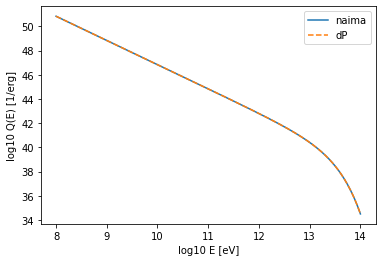

In [5]:
plt.plot( np.log10(dist_compare[:,0]), np.log10(Q_eval*u.erg), label="naima")
plt.plot( np.log10(dist_compare[:,0]), np.log10(dist_compare[:,1]), '--', label="dP")
plt.ylabel("log10 Q(E) [1/erg]")
plt.xlabel("log10 E [eV]")
plt.legend()

### Synchrotron emission

Define the stand-alone energies and specific fluxes to compare, and assign units:

In [6]:
sed_compare = np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radsyn.dat")
# sed_compare[:,0] has the photon energies [eV]
# sed_compare[:,1] has the luminosities per unit of energy [erg/s/erg]

In [7]:
# Convert sed_compare[:,0] to units of erg or eV
sed_compare_energy_sync_eV = sed_compare[:,0]*u.eV
sed_compare_energy_sync_erg = sed_compare_energy_sync_eV.to( u.erg)
# Convert sed_compare[:,1] to units of erg/s/cm^2
sed_compare_sync = sed_compare_energy_sync_erg * sed_compare[:,1] / (u.second * 4*np.pi*(1*u.kpc)**2)
sed_compare_sync = sed_compare_sync.to( u.erg / u.s / u.cm / u.cm)

Get the corresponding sed from naima:

In [8]:
# Get naima sed
B = 1E-2*u.G
distance = 1*u.kpc
Eemin=1e8*u.eV
SYN = naima.models.Synchrotron(Q, B=B, Eemin=Eemin)
sed_SYN = SYN.sed(sed_compare_energy_sync_eV, distance=distance) # erg/s/cm^2

Plot and compare:

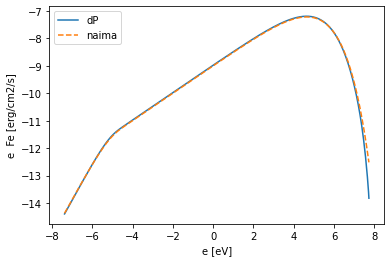

In [9]:
plt.plot( np.log10(sed_compare_energy_sync_eV/u.eV), np.log10( sed_compare_sync * u.cm*u.cm*u.second / (u.erg )), label='dP')
plt.plot( np.log10(sed_compare_energy_sync_eV/u.eV), np.log10( sed_SYN * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.ylabel( 'e  Fe [erg/cm2/s]')
plt.xlabel( 'e [eV]')
plt.legend()

### SSC emision

Define the stand-alone energies and specific fluxes to compare, and assign units:

In [10]:
sed_compare = np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radssc.dat")
# sed_compare[:,0] are the photon energies [eV]
# sed_compare[:,1] are the luminosities per unit of energy [erg/s/erg]
sed_compare_energy_ssc_eV = sed_compare[:,0]*u.eV
sed_compare_energy_ssc_erg = sed_compare_energy_ssc_eV.to( u.erg)

In [11]:
# Convert sed_compare[:,1] to units of erg/s/cm^2 
sed_compare_ssc = sed_compare_energy_ssc_erg * sed_compare[:,1] / (u.second * 4*np.pi*((1*u.kpc).to(u.cm))**2)

Get the seed photons for SSC from naima, and convert units:

In [12]:
Lsy = SYN.flux(sed_compare_energy_sync_erg, distance=0*u.cm)

In [13]:
R = 0.01 *  (1*u.pc).to(u.cm)
c = 2.99792458e10 * u.cm / u.second
phn_sy = Lsy / (4 * np.pi * R**2 * c) * 2.24 # This is the specific density of photons

In [14]:
phn_sy = phn_sy.to(1/u.erg/u.cm/u.cm/u.cm)

In [15]:
IC

NameError: name 'IC' is not defined

Get the SSC sed from naima:

In [16]:
IC = naima.models.InverseCompton(Q, seed_photon_fields=[['SSC', sed_compare_energy_sync_eV, phn_sy]], Eemin=Eemin)
sed_IC = IC.sed(sed_compare_energy_ssc_eV, distance=distance)

/home/fglsma/.local/lib/python3.6/site-packages/astropy/units/quantity.py:477: RuntimeWarning: divide by zero encountered in log10
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


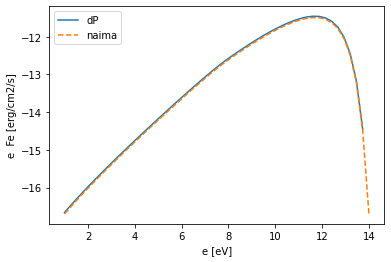

In [17]:
plt.plot( np.log10(sed_compare_energy_ssc_eV/u.eV), np.log10( sed_compare_ssc * u.cm*u.cm*u.second / u.erg ), label='dP')
plt.plot( np.log10(sed_compare_energy_ssc_eV/u.eV), np.log10( sed_IC * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.ylabel( 'e  Fe [erg/cm2/s]')
plt.xlabel( 'e [eV]')
plt.legend()

## Sync + SSC

Put everything together and compare:

/home/fglsma/.local/lib/python3.6/site-packages/astropy/units/quantity.py:477: RuntimeWarning: divide by zero encountered in log10
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


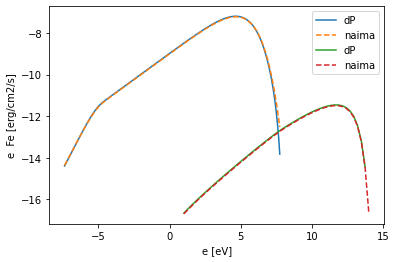

In [19]:
plt.plot( np.log10(sed_compare_energy_sync_eV/u.eV), np.log10( sed_compare_sync * u.cm*u.cm*u.second / (u.erg )), label='dP')
plt.plot( np.log10(sed_compare_energy_sync_eV/u.eV), np.log10( sed_SYN * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.plot( np.log10(sed_compare_energy_ssc_eV/u.eV), np.log10( sed_compare_ssc * u.cm*u.cm*u.second / u.erg ), label='dP')
plt.plot( np.log10(sed_compare_energy_ssc_eV/u.eV), np.log10( sed_IC * u.cm*u.cm*u.second / (u.erg )), '--', label='naima')
plt.ylabel( 'e  Fe [erg/cm2/s]')
plt.xlabel( 'e [eV]')
plt.legend()